# Modul 2 — Statistik Inferensial
Dua pertanyaan nyata:
1. **Apakah energi per ton katoda lebih tinggi pada hari downtime?** (uji beda dua kelompok)
2. **Apakah proporsi Grade A berbeda antar bulan?** (uji proporsi / independensi)

Pola kerja setiap uji: hipotesis → cek asumsi → uji → ukuran efek → interval kepercayaan → kesimpulan dalam bahasa operasional.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

XLSX = "Smelter_Data_Lanjutan.xlsx"
try:
    from google.colab import files
    if not os.path.exists(XLSX): files.upload()
except ImportError:
    pass
S = pd.read_excel(XLSX, sheet_name=None)
h, qc = S["Data_Harian"], S["QC_Lab"]
for df in (h, qc): df["Tanggal"] = pd.to_datetime(df["Tanggal"])
rng = np.random.default_rng(42)

Saving Smelter_Data_Lanjutan.xlsx to Smelter_Data_Lanjutan.xlsx


## A. Energi per ton: hari downtime vs hari normal
**H0:** rata-rata energi/t sama. **H1:** berbeda. Kelompok: hari dengan `Jam_Downtime > 0` vs `= 0`.

In [ ]:
h["Ada_Downtime"] = h.Jam_Downtime > 0
a = h.loc[h.Ada_Downtime, "Energi_per_t_Katoda_MWh"].values     # hari downtime
b = h.loc[~h.Ada_Downtime, "Energi_per_t_Katoda_MWh"].values    # hari normal
print(f"n downtime={len(a)}, n normal={len(b)}")
print(f"mean downtime={a.mean():.4f}  mean normal={b.mean():.4f}  selisih={a.mean()-b.mean():+.4f} MWh/t ({(a.mean()/b.mean()-1)*100:+.1f}%)")

n downtime=67, n normal=206
mean downtime=1.5127  mean normal=1.4560  selisih=+0.0567 MWh/t (+3.9%)


### Cek asumsi
- **Normalitas** (Shapiro–Wilk): p < 0,05 berarti sebaran menyimpang dari normal.
- **Varians sama** (Levene): menentukan apakah memakai uji t Student atau Welch. Welch lebih aman, jadi dipakai default.

Shapiro downtime: p=0.003 | normal: p=0.000
Levene (varians sama?): p=0.004


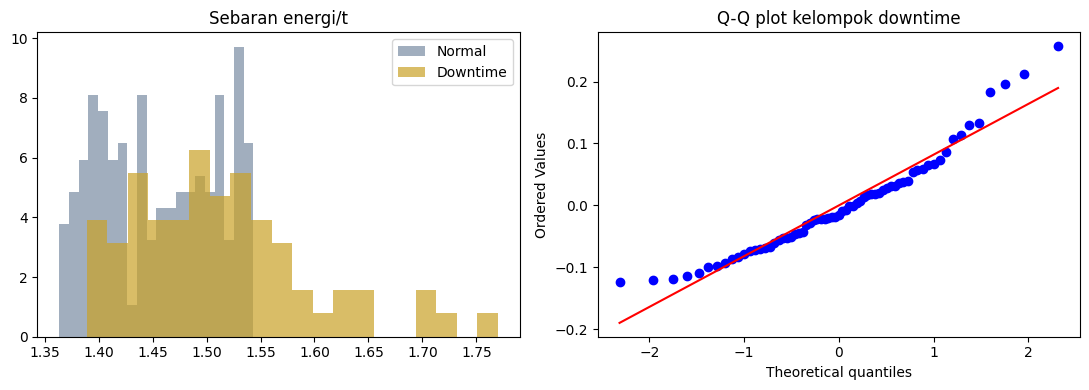

In [ ]:
print("Shapiro downtime: p=%.3f | normal: p=%.3f" % (stats.shapiro(a).pvalue, stats.shapiro(b).pvalue))
print("Levene (varians sama?): p=%.3f" % stats.levene(a, b).pvalue)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(b, bins=20, alpha=.7, label="Normal", color="#7A8CA3", density=True)
ax[0].hist(a, bins=20, alpha=.7, label="Downtime", color="#C9A227", density=True); ax[0].legend(); ax[0].set_title("Sebaran energi/t")
stats.probplot(a - a.mean(), plot=ax[1]); ax[1].set_title("Q-Q plot kelompok downtime")
plt.tight_layout(); plt.show()

### Uji Welch + alternatif non-parametrik + ukuran efek + bootstrap

In [ ]:
t = stats.ttest_ind(a, b, equal_var=False)
u = stats.mannwhitneyu(a, b, alternative="two-sided")
print(f"Welch t-test      : t={t.statistic:.3f}, p={t.pvalue:.2e}")
print(f"Mann-Whitney U    : U={u.statistic:.0f}, p={u.pvalue:.2e}")

# Cohen's d memakai simpangan baku gabungan; Hedges' g = koreksi sampel kecil
sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
d = (a.mean() - b.mean()) / sp
g = d * (1 - 3 / (4*(len(a)+len(b)) - 9))
print(f"Cohen's d={d:.2f}  Hedges' g={g:.2f}  (|d|: 0.2 kecil, 0.5 sedang, 0.8 besar)")

# Bootstrap: ambil ulang sampel dengan pengembalian 10.000 kali -> sebaran selisih rata-rata
boot = np.array([rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(10000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Selisih rata-rata: {a.mean()-b.mean():+.4f}, CI95% bootstrap [{lo:+.4f}, {hi:+.4f}]")

Welch t-test      : t=5.258, p=1.06e-06
Mann-Whitney U    : U=9733, p=4.56e-07
Cohen's d=0.91  Hedges' g=0.91  (|d|: 0.2 kecil, 0.5 sedang, 0.8 besar)
Selisih rata-rata: +0.0567, CI95% bootstrap [+0.0364, +0.0782]


### Efek hari downtime itu sendiri, atau karena durasinya?
Regresi sederhana: energi/t terhadap jam downtime pada hari downtime saja.

In [ ]:
dd = h[h.Ada_Downtime]
r = stats.linregress(dd.Jam_Downtime, dd.Energi_per_t_Katoda_MWh)
print(f"Hanya hari downtime (n={len(dd)}): kemiringan={r.slope:+.4f} MWh/t per jam, r={r.rvalue:.2f}, p={r.pvalue:.3g}")
rho = stats.spearmanr(dd.Jam_Downtime, dd.Energi_per_t_Katoda_MWh)
print(f"Spearman rho={rho.statistic:.2f}, p={rho.pvalue:.3g}")

Hanya hari downtime (n=67): kemiringan=+0.0164 MWh/t per jam, r=0.79, p=2.16e-15
Spearman rho=0.63, p=1.45e-08


**Cara membaca:** p kecil + efek besar = perbedaan nyata dan penting. p kecil + efek sangat kecil = nyata secara statistik tetapi mungkin tidak penting secara operasional. Selalu laporkan keduanya.

## B. Proporsi Grade A antar bulan
**H0:** peluang Grade A sama di semua bulan. Data: tabel kontingensi bulan × status.

In [ ]:
qc["Bulan"] = qc.Tanggal.dt.month
qc["GradeA"] = (qc.Status_Mutu == "Grade A").astype(int)
tab = qc.groupby("Bulan").GradeA.agg(["sum", "count"]); tab.columns = ["GradeA", "Batch"]
tab["OffGrade"] = tab.Batch - tab.GradeA; tab["Prop_A_%"] = tab.GradeA / tab.Batch * 100
print(tab.round(1)); print("Total Grade A: %d/%d" % (tab.GradeA.sum(), tab.Batch.sum()))

       GradeA  Batch  OffGrade  Prop_A_%
Bulan                                   
1          31     31         0     100.0
2          27     28         1      96.4
3          31     31         0     100.0
4          28     30         2      93.3
5          30     31         1      96.8
6          25     30         5      83.3
7          29     31         2      93.5
8          29     31         2      93.5
9          28     30         2      93.3
Total Grade A: 258/273


In [ ]:
ct = tab[["GradeA", "OffGrade"]].values
chi2, p, dof, exp = stats.chi2_contingency(ct)
print(f"Chi-square: chi2={chi2:.2f}, dof={dof}, p={p:.3f}")
print(f"Sel dengan frekuensi harapan < 5: {(exp < 5).sum()} dari {exp.size}  -> asumsi chi-square {'TERLANGGAR' if (exp<5).any() else 'aman'}")
v = np.sqrt(chi2 / (ct.sum() * (min(ct.shape) - 1)))
print(f"Cramer's V = {v:.3f}")

# Uji permutasi: tidak bergantung pada asumsi sampel besar
def chi2_stat(status, bulan):
    obs = pd.crosstab(bulan, status).values
    e = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
    return ((obs - e) ** 2 / e).sum()
obs_stat = chi2_stat(qc.GradeA.values, qc.Bulan.values)
perm = np.array([chi2_stat(rng.permutation(qc.GradeA.values), qc.Bulan.values) for _ in range(5000)])
print(f"Permutasi: statistik={obs_stat:.2f}, p={(perm >= obs_stat).mean():.3f}")

Chi-square: chi2=11.59, dof=8, p=0.170
Sel dengan frekuensi harapan < 5: 9 dari 18  -> asumsi chi-square TERLANGGAR
Cramer's V = 0.206
Permutasi: statistik=11.59, p=0.156


### Uji tren Cochran–Armitage (apakah proporsi naik/turun menurut bulan?)

In [ ]:
x = tab.index.values.astype(float); n = tab.Batch.values; r_ = tab.GradeA.values
pbar = r_.sum() / n.sum()
T = ((x - (n*x).sum()/n.sum()) * (r_ - n*pbar)).sum()
varT = pbar*(1-pbar) * (n * (x - (n*x).sum()/n.sum())**2).sum()
z = T / np.sqrt(varT); pz = 2 * (1 - stats.norm.cdf(abs(z)))
print(f"Cochran-Armitage: z={z:.2f}, p={pz:.3f}  ({'ada' if pz<.05 else 'tidak ada'} tren linear menurut bulan)")

Cochran-Armitage: z=-1.83, p=0.068  (tidak ada tren linear menurut bulan)


### Pembandingan berpasangan + koreksi Holm
9 bulan = 36 pasangan. Menguji 36 kali menaikkan peluang "temuan palsu" — karena itu p-value dikoreksi (Holm).

In [ ]:
from itertools import combinations
baris = []
for i, j in combinations(tab.index, 2):
    tt = [[tab.GradeA[i], tab.OffGrade[i]], [tab.GradeA[j], tab.OffGrade[j]]]
    baris.append((i, j, stats.fisher_exact(tt)[1]))
pw = pd.DataFrame(baris, columns=["bulan_i", "bulan_j", "p_mentah"])
m_ = len(pw); urut = pw.p_mentah.sort_values().index
holm = pd.Series(index=pw.index, dtype=float); prev = 0
for k, idx in enumerate(urut):
    prev = max(prev, min(1, pw.p_mentah[idx] * (m_ - k))); holm[idx] = prev
pw["p_Holm"] = holm
print(f"{(pw.p_mentah<.05).sum()} pasangan p<0.05 sebelum koreksi; {(pw.p_Holm<.05).sum()} setelah Holm")
print(pw.sort_values("p_mentah").head(5).round(3).to_string(index=False))

2 pasangan p<0.05 sebelum koreksi; 0 setelah Holm
 bulan_i  bulan_j  p_mentah  p_Holm
       1        6     0.024   0.862
       3        6     0.024   0.862
       5        6     0.104   1.000
       2        6     0.195   1.000
       3        4     0.238   1.000


**Kesimpulan modul 2.**

*   Energi per ton pada hari downtime lebih tinggi 0,057 MWh/t (+3,9%). Efeknya besar (Cohen’s d 0,91) dan CI bootstrap 0,036–0,078 tidak melewati nol.
*   Di antara hari downtime, setiap jam henti menambah sekitar 0,016 MWh/t (r = 0,79).
*   Proporsi Grade A antar bulan tidak berbeda nyata (chi-square p = 0,170, permutasi p = 0,156). Juni terlihat buruk (83,3%), tetapi tidak bertahan setelah koreksi Holm. Asumsi chi-square dilanggar karena 9 dari 18 sel frekuensinya terlalu kecil, jadi uji permutasi lebih dipercaya.




